# Wine: logistic vs quadratic logistic regression (small classification dataset)

**Data:** UCI *Wine*, 178 wines from three cultivars (grape varieties), 13 numeric features
from a chemical analysis (alcohol, flavanoids, proline, ...).
**Target:** the cultivar (1, 2 or 3). **Metric:** logistic loss (log-loss).

Step 4 of the lab: steps 1-3 repeated with **logistic regression**. With 3 classes the model
is *multinomial* (softmax): one weight vector per class.

Code: the loader `lab/data_wine.py`, the sampler `lab/sampler.py`, the models `lab/models.py`,
the experiment loop `lab/experiment.py` and the plots `lab/plotting.py`.

In [1]:
import sys
sys.path.append("..")  # make the lab/ package (one folder up) importable

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve
from lab.sampler import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

# Some scikit-learn versions warn on every fit that C=inf means "no penalty".
# That is exactly what we want (see lab/models.py), so the message is hidden.
import warnings
warnings.filterwarnings("ignore", message="Setting penalty=None")

In [2]:
DATASET = "wine"
TASK = "classification"
KINDS = ["logistic", "quadratic_logistic"]
N_REPEATS = 20   # cheap on 178 rows, and more repeats give smoother bands

## Load the data
No missing values, all 13 features numeric. Their scales differ a lot (hue ~1, proline ~1000);
the pipeline standardizes them, fitted on each training sample only.

In [3]:
from lab.data_wine import load_wine

X, y = load_wine()
print(X.shape)
display(X.describe().T[["mean", "std", "min", "max"]])
print("class counts:")
print(y.value_counts().sort_index())

(178, 13)


,mean,std,min,max
alcohol,13,0.8118,11.03,14.83
malic_acid,2.336,1.117,0.74,5.8
ash,2.367,0.2743,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.6,30
magnesium,99.74,14.28,70,162
total_phenols,2.295,0.6259,0.98,3.88
flavanoids,2.029,0.9989,0.34,5.08
nonflavanoid_phenols,0.3619,0.1245,0.13,0.66
proanthocyanins,1.591,0.5724,0.41,3.58
color_intensity,5.058,2.318,1.28,13


class counts:
cultivar
1    59
2    71
3    48
Name: count, dtype: int64


## Train / validation split
20% of the wines are set aside as the validation set and never used for fitting.

**How we split:** randomly, **stratified on the cultivar** (`split_wine` in `lab/data_wine.py`).
Every wine is a separate bottle, so the rows are independent and there is no group or time
structure to respect. With only ~36 validation wines a plain random split could leave one
cultivar under-represented; stratifying keeps the proportions 59 : 71 : 48 in both parts.
Cross-validation uses the default `StratifiedKFold` for the same reason.

In [4]:
from lab.data_wine import split_wine

X_train, X_val, y_train, y_val = split_wine(X, y)
print(f"training part: {len(X_train)} rows, validation: {len(X_val)} rows")
display(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                      "validation": y_val.value_counts().sort_index()}))

training part: 142 rows, validation: 36 rows


,train,validation
cultivar,,
1,47,12
2,57,14
3,38,10


In [5]:
# How many features does each model actually see? (after one-hot / squaring)
# Compare these numbers with the training-set sizes on the x-axis below.
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

            logistic: 13 features
  quadratic_logistic: 104 features


Multinomial logistic regression learns one weight per feature **and class**, so the
plain model has 3 x 13 + 3 = 42 parameters and the quadratic one 3 x 104 + 3 = 315, more than
the whole training part (142 wines).

## Step 4 (= steps 1 & 2 with logistic regression): learning curves

In [6]:
# Training-set sizes 10, 20, ..., up to the whole training part.
sizes = linear_sizes(10, len(X_train), 10)
if sizes[-1] != len(X_train):
    sizes.append(len(X_train))
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK, verbose=False)
curve.to_csv(RESULTS_DIR / f"{DATASET}_curve.csv", index=False)

stats = summarize(curve)
display(stats)

[10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 142]


model size train_score                                \
                                   mean       std    median       q25   
0             logistic   10   0.0001094 1.355e-05 0.0001106 9.884e-05   
1             logistic   20   0.0001366 1.649e-05 0.0001423 0.0001262   
2             logistic   30   0.0001591 2.756e-05 0.0001552 0.0001358   
3             logistic   40   0.0001903 4.873e-05 0.0001891 0.0001625   
4             logistic   50   0.0002077 4.266e-05 0.0002041 0.0001851   
5             logistic   60   0.0001979 7.052e-05  0.000216 0.0001424   
6             logistic   70   0.0002038  7.15e-05 0.0001801 0.0001596   
7             logistic   80   0.0001687  5.22e-05 0.0001587 0.0001416   
8             logistic   90   0.0001639 4.795e-05 0.0001678 0.0001375   
9             logistic  100   0.0002032 8.259e-05 0.0001939 0.0001402   
10            logistic  110    0.000188 5.825e-05 0.0001817 0.0001479   
11            logistic  120   0.0001897 5.262e-05 0.0001868 0.0001503   
12            logistic  130   0.0002196 5.514e-05 0.0002298 0.0001883   
13            logistic  140    0.000223 4.558e-05  0.000241 0.0002063   
14            logistic  142   0.0002065         0 0.0002065 0.0002065   
15  quadratic_logistic   10   0.0001134 2.992e-05 0.0001155 8.571e-05   
16  quadratic_logistic   20   0.0001202 2.374e-05 0.0001192  0.000102   
17  quadratic_logistic   30   0.0001252 2.891e-05 0.0001255 0.0001001   
18  quadratic_logistic   40   0.0001166 3.403e-05 0.0001089 9.419e-05   
19  quadratic_logistic   50   0.0001414  3.62e-05 0.0001383 0.0001251   
20  quadratic_logistic   60   0.0001365 3.542e-05 0.0001348 0.0001099   
21  quadratic_logistic   70   0.0001617 4.644e-05 0.0001708 0.0001258   
22  quadratic_logistic   80   0.0001507 3.298e-05 0.0001401 0.0001272   
23  quadratic_logistic   90   0.0001578 3.332e-05  0.000154 0.0001379   
24  quadratic_logistic  100   0.0001641 3.338e-05   0.00016 0.0001366   
25  quadratic_logistic  110   0.0001647 4.004e-05 0.0001627 0.0001321   
26  quadratic_logistic  120   0.0001612 3.879e-05 0.0001569 0.0001308   
27  quadratic_logistic  130   0.0001501 3.618e-05 0.0001351 0.0001285   
28  quadratic_logistic  140   0.0001556 8.551e-06 0.0001531 0.0001506   
29  quadratic_logistic  142   0.0001504         0 0.0001504 0.0001504   

             val_score                                  
         q75      mean     std  median     q25     q75  
0  0.0001167    0.2606  0.1622  0.2191  0.1491  0.3301  
1  0.0001463    0.1817  0.1544  0.1121 0.08591  0.2651  
2  0.0001726    0.1531  0.1271  0.1107 0.07987  0.1673  
3   0.000207    0.1465   0.119  0.1193 0.05036  0.1851  
4  0.0002416    0.1271 0.09949  0.1056 0.04983  0.1837  
5  0.0002364    0.1743  0.1237  0.1439 0.07166  0.2473  
6  0.0002417   0.09652 0.08648 0.07777  0.0249  0.1491  
7  0.0001754    0.1083 0.06689 0.09783 0.06647   0.119  
8  0.0001904    0.1181   0.067   0.108 0.07417  0.1498  
9  0.0002645   0.07356 0.03793  0.0775 0.04296 0.09852  
10 0.0002218   0.08356 0.04275 0.07654 0.06099  0.1021  
11 0.0002127   0.07543  0.0325 0.07469 0.06048 0.09225  
12 0.0002527   0.08077 0.03241  0.0803 0.06613 0.09345  
13 0.0002555   0.06362 0.02264 0.05753 0.05474 0.06281  
14 0.0002065   0.07735       0 0.07735 0.07735 0.07735  
15 0.0001361    0.3696  0.1413  0.3564  0.2736  0.4819  
16 0.0001369    0.3592  0.2784  0.2933  0.1292  0.5384  
17 0.0001475    0.2843  0.2341  0.2258  0.1078  0.3534  
18 0.0001427    0.4415  0.2969  0.4146  0.1752  0.6954  
19 0.0001483    0.3402  0.2499  0.3124  0.1495  0.5204  
20 0.0001584      0.46  0.3741  0.3293   0.168  0.6957  
21  0.000191    0.2855  0.1914  0.2628  0.1618  0.3284  
22  0.000178    0.3811  0.1903  0.3526   0.279  0.4636  
23 0.0001805    0.3807  0.2255  0.3743  0.2505  0.5169  
24 0.0001878    0.2757   0.152   0.295  0.1667  0.3705  
25 0.0001943    0.2968  0.1612  0.2582  0.1678  0.3593  
26  0.000194    0.2991   0.141  0.2834  0.2177  0.3384  
27 0.0001764    0.3277  0.1

baseline validation log-loss: 1.0897


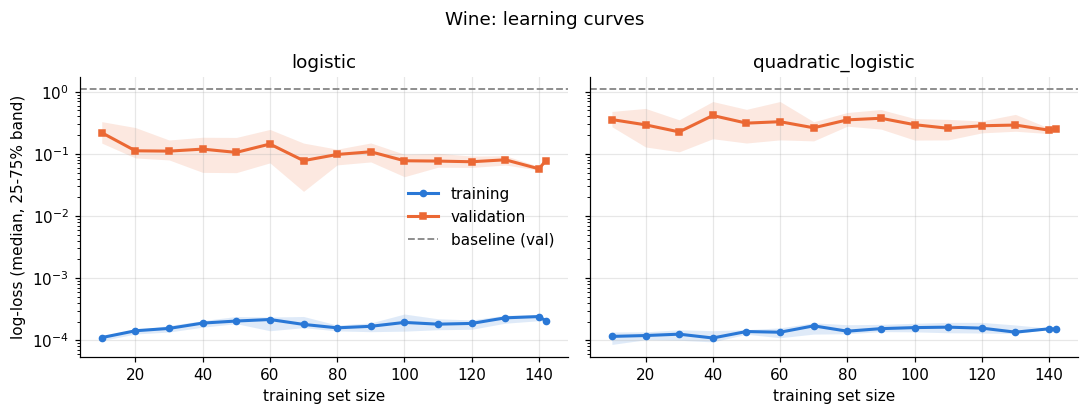

In [7]:
# Reference: always predict the class proportions of the training part.
# Its log-loss is the entropy of the class distribution (~1.09 for 3 balanced-ish classes).
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation log-loss: {baseline:.4f}")

# log y-axis: the training loss (~1e-4) and validation loss (~0.1) differ by 1000x.
fig = plot_learning_curve(curve, "log-loss", "Wine: learning curves", baseline=baseline,
                          log_y=True,
                          path=FIGURES_DIR / f"{DATASET}_learning_curves.png")

### What the curves show

**Training error (blue).** The training log-loss is tiny (~1e-4) at **every** size, even on
the whole training part. The three cultivars are *linearly separable* in the 13 chemical
features: there is a set of planes that puts every training wine on the right side. Without
regularization the best weights are then infinitely large (the larger the weights, the closer
the predicted probabilities get to exactly 0 and 1, and the smaller the loss), so the solver
keeps growing them until it hits its iteration limit. The training loss we see is set by that
limit, not by the data. Unlike the regression datasets, the training curve never rises,
because 142 wines are still not enough to make the classes overlap.

**Validation error (orange).** For the plain model the validation log-loss falls from ~0.2
at 10 wines to ~0.06-0.08 with the whole training part, far below the baseline (~1.09 =
always predicting the class proportions). Even 10 wines (3-4 per cultivar) give a usable
classifier: the cultivars differ strongly in a few features (flavanoids, proline, colour
intensity). The remaining gap to the training loss comes from the few validation wines the
model gets wrong (3 of 36 at full size, ~92% accuracy): each one costs `-log(p)` for the
probability `p` it gave the true cultivar.

**Linear vs quadratic.** The quadratic model has 104 features, i.e. 315 parameters with 3
classes, more than the whole training part. It separates every sample perfectly as well, but
its boundary is far more flexible than the data justify, so its validation log-loss stays
around 0.25-0.4 and barely improves with more data: we only see the "p > n" regime. More
parameters do not help here because a linear boundary already separates the classes; the
extra flexibility only adds variance.

**Variability.** The bands are wide for small samples (which wines are drawn matters a lot)
and narrow towards the full size; at 142 every repeat uses the same wines.

## Step 3 for classification: cross-validation
5-fold stratified CV on the training part only (the validation set stays untouched). Each
fold trains on ~114 wines and is scored on the remaining ~28.

In [8]:
cv = cross_validate_models(X_train, y_train, KINDS, TASK, k=5)
cv.to_csv(RESULTS_DIR / f"{DATASET}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,logistic,0.06673,0.07811,142,0.0002065,0.07735
1,quadratic_logistic,0.1296,0.1526,142,0.0001504,0.2482


CV chooses: logistic


### CV vs. the learning curves

CV prefers the **plain logistic** model, in agreement with the validation curves.

- The CV log-loss is far above the training loss: the training loss is measured on the wines
  the model was fitted on, and here it is ~0 by construction (separable data).
- CV and validation are on the same order (~0.07 for logistic, ~0.13-0.25 for quadratic), but
  `cv_std` is about as large as `cv_mean`: with ~28 wines per fold, one or two confidently
  misclassified wines change the loss of a fold a lot. Our validation set (36 wines) is one
  such draw; CV averages over 5 of them and is the more reliable estimate.
- Each CV model is trained on ~114 instead of 142 wines, i.e. CV sits a bit to the left on
  the learning curve.
- Log-loss judges the *probabilities*, not just the predicted class. Fitted on the whole
  training part, the plain model gets 3 of the 36 validation wines wrong, but only with 52-63%
  confidence; the quadratic model gets 4 wrong, two of them with 96-97% confidence. Those two
  confident mistakes alone explain most of its higher log-loss: the classic sign of a model
  with too many parameters for the data.